In [3]:
%pip install pyarrow

  Using cached pyarrow-26.0.0-cp313-cp313-win_amd64.whl.metadata (3.0 kB)
Using cached pyarrow-26.0.0-cp313-cp313-win_amd64.whl (28.5 MB)
Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
from pathlib import Path

project = Path(r"C:\Users\VARUN\Downloads\demand-planner")

sheets = pd.read_excel(project / "data" / "online_retail_II.xlsx", sheet_name=None)
df = pd.concat(sheets.values(), ignore_index=True)

df.to_parquet(project / "data" / "raw.parquet")
print(df.shape)
df.head()

ArrowInvalid: ("Could not convert 'C489449' with type str: tried to convert to int64", 'Conversion failed for column Invoice with type object')

In [6]:
df["Invoice"] = df["Invoice"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)

df.to_parquet(project / "data" / "raw.parquet")
print(df.shape)
df.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
text_cols = df.select_dtypes(include="object").columns
print("Text columns:", list(text_cols))

for col in text_cols:
    df[col] = df[col].astype("string")

df.to_parquet(project / "data" / "raw.parquet")
print(df.shape)
df.head()

Text columns: ['Invoice', 'StockCode', 'Description', 'Country']
(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [8]:
df["Description"].map(type).value_counts()

Description
<class 'str'>      1062985
<class 'float'>       4382
<class 'int'>            4
Name: count, dtype: int64

In [12]:
def first_look(df):
    summary = pd.DataFrame({
        "blanks": df.isna().sum(),
        "unique_values": df.nunique(),
        "example": df.apply(lambda c: c.dropna().iloc[0] if c.notna().any() else None),
    })
    print(summary)
    for col in df.columns:
        print(f"\n--- {col}: most common values ---")
        print(df[col].value_counts(dropna=False).head(5))

In [13]:
df = pd.read_parquet(project / "data" / "raw.parquet")
first_look(df)

             blanks  unique_values                              example
Invoice           0          53628                               489434
StockCode         0           5305                                85048
Description    4382           5698  15CM CHRISTMAS GLASS BALL 20 LIGHTS
Quantity          0           1057                                   12
InvoiceDate       0          47635                  2009-12-01 07:45:00
Price             0           2807                                 6.95
Customer ID  243007           5942                              13085.0
Country           0             43                       United Kingdom

--- Invoice: most common values ---
Invoice
537434    1350
538071    1304
537638    1202
537237    1194
536876    1186
Name: count, dtype: int64

--- StockCode: most common values ---
StockCode
85123A    5829
22423     4424
85099B    4216
21212     3318
20725     3259
Name: count, dtype: int64

--- Description: most common values ---
Description
WHI

In [15]:
print(df.shape)

(1067371, 8)


In [14]:
print((df["Quantity"] < 0).sum(), "rows with negative quantity")
print(df["Invoice"].str.startswith("C").sum(), "rows whose invoice starts with C")
print((df["Price"] <= 0).sum(), "rows with zero or negative price")
print(df.duplicated().sum(), "fully duplicated rows")

22950 rows with negative quantity
19494 rows whose invoice starts with C
6207 rows with zero or negative price
34335 fully duplicated rows


In [16]:
neg  = df["Quantity"] < 0                   # True where the quantity is negative
is_c = df["Invoice"].str.startswith("C")    # True where the invoice starts with C

In [17]:
print((is_c & ~neg).sum(), "C invoices with a positive quantity")   # we expect 0
print((neg & ~is_c).sum(), "negative, but not a C invoice")         # should be 3,456

mystery = df[neg & ~is_c]
print(mystery["Price"].describe())                                  # what prices do they have?
print(mystery["Customer ID"].isna().mean(), "share with no customer")
print(mystery["Description"].value_counts(dropna=False).head(15))   # what were they called?

1 C invoices with a positive quantity
3457 negative, but not a C invoice
count    3457.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: Price, dtype: float64
1.0 share with no customer
Description
<NA>                      2689
check                      123
damages                     84
?                           83
damaged                     78
missing                     27
sold as set on dotcom       20
Damaged                     17
smashed                      9
thrown away                  9
Unsaleable, destroyed.       9
dotcom                       8
??                           7
damages?                     7
crushed                      6
Name: count, dtype: Int64


In [18]:
prefix = df["Invoice"].str.extract(r"^([A-Za-z]*)")[0]
print(prefix.value_counts())

0
     1047871
C      19494
A          6
Name: count, dtype: int64


In [19]:
free = df[df["Price"] <= 0]
print((df["Price"] < 0).sum(), "rows with a NEGATIVE price")
print(free["Description"].value_counts(dropna=False).head(15))
print(free["Customer ID"].isna().mean(), "share with no customer")

5 rows with a NEGATIVE price
Description
<NA>                            4382
check                            162
?                                 92
damages                           84
damaged                           81
found                             28
missing                           27
sold as set on dotcom             20
Damaged                           17
adjustment                        16
OWL DOORSTOP                      15
dotcom                            12
POLYESTER FILLER PAD 45x45cm      12
amazon                            11
POLYESTER FILLER PAD 40x40cm      10
Name: count, dtype: Int64
0.9885613017560818 share with no customer


In [20]:
# 1. The one odd C invoice with a positive quantity: what is it?
print(df[is_c & ~neg])

# 2. The A invoices: are they the 5 negative-price rows?
print(df[prefix == "A"])

# 3. Which stock codes aren't normal products?
pattern = r"^\d{5}[A-Za-z]*$"       # 5 digits, optionally followed by letters, e.g. 85123A
odd_codes = df[~df["StockCode"].str.match(pattern)]
print(odd_codes["StockCode"].value_counts().head(25))
print(odd_codes.drop_duplicates("StockCode")[["StockCode", "Description"]].head(40))

       Invoice StockCode Description  Quantity         InvoiceDate   Price  \
76799  C496350         M      Manual         1 2010-02-01 08:24:00  373.57   

       Customer ID         Country  
76799          NaN  United Kingdom  
        Invoice StockCode      Description  Quantity         InvoiceDate  \
179403  A506401         B  Adjust bad debt         1 2010-04-29 13:36:00   
276274  A516228         B  Adjust bad debt         1 2010-07-19 11:24:00   
403472  A528059         B  Adjust bad debt         1 2010-10-20 12:04:00   
825443  A563185         B  Adjust bad debt         1 2011-08-12 14:50:00   
825444  A563186         B  Adjust bad debt         1 2011-08-12 14:51:00   
825445  A563187         B  Adjust bad debt         1 2011-08-12 14:52:00   

           Price  Customer ID         Country  
179403 -53594.36          NaN  United Kingdom  
276274 -44031.79          NaN  United Kingdom  
403472 -38925.87          NaN  United Kingdom  
825443  11062.06          NaN  United Kingdo

In [21]:
print(df[df["StockCode"].isin(["S", "CRUK"])][["StockCode", "Description", "Price"]].drop_duplicates("StockCode"))

       StockCode      Description  Price
114061         S          SAMPLES   73.8
842969      CRUK  CRUK Commission    1.6


In [22]:
NON_PRODUCT = {"POST", "DOT", "C2", "D", "M", "B", "ADJUST",
               "BANK CHARGES", "AMAZONFEE", "S", "CRUK"}   # remove S and CRUK from this list if your check shows they're products

def clean(raw):
    df = raw.copy()        # work on a copy, so the raw data stays untouched
    log = []               # each rule records how many rows it removed

    def drop(mask, reason):
        nonlocal df
        log.append((reason, int(mask.sum())))
        df = df[~mask]

    # Rule 1: exact duplicate rows (assumed to be export errors)
    drop(df.duplicated(), "exact duplicate rows")

    # Tidy-up: make codes consistent, so 'm' and 'M' count as the same code
    df["StockCode"] = df["StockCode"].str.strip().str.upper()

    # Rule 2: bad-debt adjustments
    drop(df["Invoice"].str.startswith("A"), "bad-debt adjustments (A invoices)")

    # Rule 3: non-product codes: postage, fees, tests, gift vouchers
    nonprod = (df["StockCode"].isin(NON_PRODUCT)
               | df["StockCode"].str.startswith(("GIFT", "TEST")))
    drop(nonprod, "non-product codes")

    # Rule 4: zero or negative prices (stock adjustments, system entries)
    drop(df["Price"] <= 0, "zero or negative price")

    # Tidy-up: Customer ID is an ID, so make it text and drop the '.0'
    df["Customer ID"] = df["Customer ID"].astype("Int64").astype("string")

    return df, pd.DataFrame(log, columns=["rule", "rows_removed"])

In [23]:
clean_df, log = clean(df)
print(log)
print(len(df), "->", len(clean_df), "rows")

# Checks: each one should print True
print("no free or negative prices:", (clean_df["Price"] > 0).all())
print("negatives are only cancellations:",
      clean_df.loc[clean_df["Quantity"] < 0, "Invoice"].str.startswith("C").all())
print("no blank descriptions left:", clean_df["Description"].notna().all())

clean_df.to_parquet(project / "data" / "clean.parquet")

                                rule  rows_removed
0               exact duplicate rows         34335
1  bad-debt adjustments (A invoices)             6
2                  non-product codes          5791
3             zero or negative price          5964
1067371 -> 1021275 rows
no free or negative prices: True
negatives are only cancellations: True
no blank descriptions left: True


In [24]:
clean_df = pd.read_parquet(project / "data" / "clean.parquet")

# 1. Label every row with the Monday its week starts on
clean_df["week"] = clean_df["InvoiceDate"].dt.to_period("W-SUN").dt.start_time

# 2. Add up units per product per week (cancellations subtract automatically)
weekly = clean_df.groupby(["StockCode", "week"])["Quantity"].sum()
total_before = weekly.sum()

# 3. Build every product x every week, filling missing weeks with 0
weeks = pd.date_range(weekly.index.get_level_values("week").min(),
                      weekly.index.get_level_values("week").max(), freq="W-MON")
products = weekly.index.get_level_values("StockCode").unique()
full = pd.MultiIndex.from_product([products, weeks], names=["StockCode", "week"])
weekly = weekly.reindex(full, fill_value=0).reset_index(name="qty")

# 4. Keep each product from its first week of sales onward
first_week = weekly[weekly["qty"] > 0].groupby("StockCode")["week"].min()
weekly = weekly.merge(first_week.rename("first_week"), on="StockCode")
weekly = weekly[weekly["week"] >= weekly["first_week"]].drop(columns="first_week")

# 5. Drop the incomplete first and last weeks
weekly = weekly[(weekly["week"] > weeks.min()) & (weekly["week"] < weeks.max())]

# 6. A week can't have negative demand, so set those to 0
neg_weeks = (weekly["qty"] < 0).sum()
weekly["qty"] = weekly["qty"].clip(lower=0)

413761 product-weeks
4719 products, 104 weeks
2122 weeks were negative and set to 0
54.0% of product-weeks are zero


<Axes: title={'center': '85123A weekly demand'}, xlabel='week'>

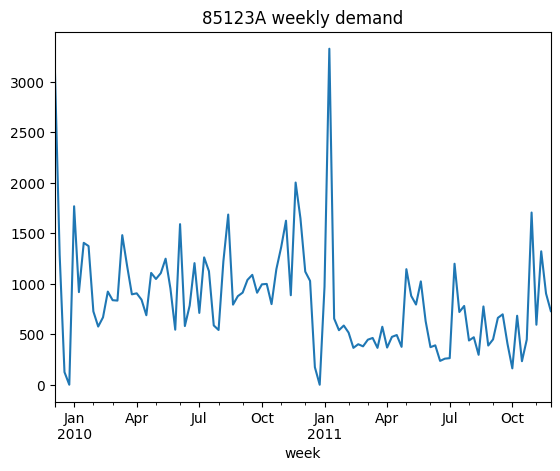

In [25]:
print(len(weekly), "product-weeks")
print(weekly["StockCode"].nunique(), "products,", weekly["week"].nunique(), "weeks")
print(neg_weeks, "weeks were negative and set to 0")
print(f"{(weekly['qty'] == 0).mean():.1%} of product-weeks are zero")

weekly.to_parquet(project / "data" / "weekly.parquet")

# Look at a best-seller and see its pattern for yourself
weekly[weekly["StockCode"] == "85123A"].set_index("week")["qty"].plot(title="85123A weekly demand")

In [26]:
def classify(q, min_weeks=26):
    if len(q) < min_weeks:
        return pd.Series({"adi": None, "cv2": None, "group": "too new"})
    sales = q[q > 0]                      # only the weeks with a sale
    if len(sales) < 2:
        return pd.Series({"adi": None, "cv2": None, "group": "too few sales"})
    adi = len(q) / len(sales)
    cv2 = (sales.std() / sales.mean()) ** 2
    if adi < 1.32:
        group = "smooth" if cv2 < 0.49 else "erratic"
    else:
        group = "intermittent" if cv2 < 0.49 else "lumpy"
    return pd.Series({"adi": adi, "cv2": cv2, "group": group})

profile = weekly.groupby("StockCode")["qty"].apply(classify).unstack()
print(profile["group"].value_counts())
print(profile.loc["85123A"])
profile.to_parquet(project / "data" / "profile.parquet")

group
lumpy            2520
erratic          1114
intermittent      418
too new           386
too few sales     150
smooth            131
Name: count, dtype: int64
adi      1.019608
cv2      0.363755
group      smooth
Name: 85123A, dtype: object


In [27]:
import numpy as np

def sba(y, alpha=0.1):
    """Returns (forecast made before each week, final forecast for next week)."""
    y = np.asarray(y, dtype=float)
    f = np.full(len(y), np.nan)        # forecasts; NaN until the first sale
    z = p = None
    q = 1                              # weeks since the last sale
    for t, d in enumerate(y):
        if z is not None:
            f[t] = (1 - alpha / 2) * z / p     # forecast using only past weeks
        if d > 0:
            if z is None:
                z, p = d, q                    # first sale: start the estimates
            else:
                z += alpha * (d - z)           # update typical order size
                p += alpha * (q - p)           # update typical gap
            q = 1
        else:
            q += 1
    final = (1 - alpha / 2) * z / p if z is not None else 0.0
    return f, final


def tsb(y, alpha=0.1, beta=0.1):
    y = np.asarray(y, dtype=float)
    f = np.full(len(y), np.nan)
    z = p = None
    q = 1
    for t, d in enumerate(y):
        if z is not None:
            f[t] = p * z
        if z is None:
            if d > 0:
                z, p = d, 1 / q                # first sale: start the estimates
            else:
                q += 1
            continue
        if d > 0:
            p += beta * (1 - p)                # a sale: probability moves up
            z += alpha * (d - z)               # update typical order size
        else:
            p += beta * (0 - p)                # no sale: probability moves down
    final = p * z if z is not None else 0.0
    return f, final

<Axes: title={'center': 'Toy product that stops selling after week 8'}>

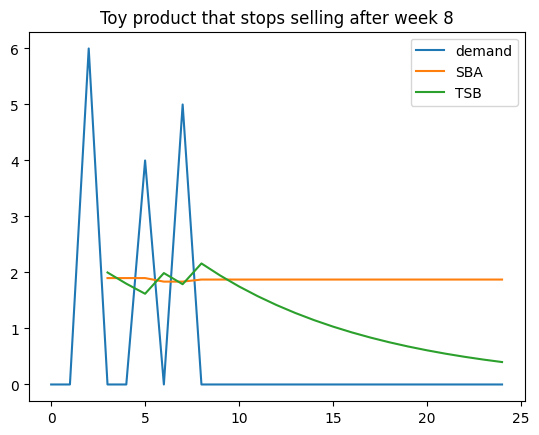

In [28]:
toy = [0, 0, 6, 0, 0, 4, 0, 5, 0, 0] + [0] * 15    # sells for a while, then stops
f_sba, _ = sba(toy)
f_tsb, _ = tsb(toy)

pd.DataFrame({"demand": toy, "SBA": f_sba, "TSB": f_tsb}).plot(
    title="Toy product that stops selling after week 8")

<Axes: title={'center': '10002'}, xlabel='week'>

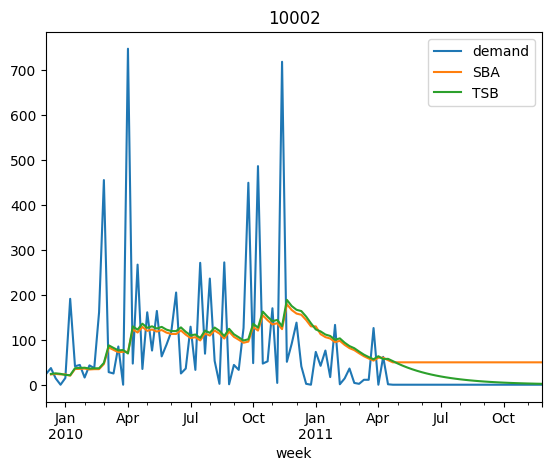

In [29]:
lumpy_code = profile[profile["group"] == "lumpy"].index[0]
y = weekly[weekly["StockCode"] == lumpy_code].set_index("week")["qty"]
f_sba, _ = sba(y)
f_tsb, _ = tsb(y)
pd.DataFrame({"demand": y, "SBA": f_sba, "TSB": f_tsb}, index=y.index).plot(title=lumpy_code)

In [30]:
cutoff = weekly["week"].max() - pd.Timedelta(weeks=26)

# Re-classify using training weeks only (no peeking at the test period)
train = weekly[weekly["week"] <= cutoff]
profile_train = train.groupby("StockCode")["qty"].apply(classify).unstack()

rows = []
for code, g in weekly.groupby("StockCode"):
    if code not in profile_train.index:
        continue
    group = profile_train.at[code, "group"]
    if group in ("too new", "too few sales"):
        continue
    y = g.set_index("week")["qty"]
    f_sba, _ = sba(y.values)
    f_tsb, _ = tsb(y.values)
    f_ma8 = y.shift(1).rolling(8, min_periods=1).mean().values   # shift(1) = only past weeks
    test = (y.index > cutoff)
    for name, f in [("MA8", f_ma8), ("SBA", f_sba), ("TSB", f_tsb)]:
        ok = test & ~np.isnan(f)
        err = f[ok] - y.values[ok]
        rows.append({"StockCode": code, "group": group, "method": name,
                     "abs_err": np.abs(err).sum(), "err": err.sum(), "n": ok.sum()})

res = pd.DataFrame(rows)
summary = res.groupby(["group", "method"])[["abs_err", "err", "n"]].sum()
summary["MAE"] = summary["abs_err"] / summary["n"]
summary["bias"] = summary["err"] / summary["n"]
print(summary[["MAE", "bias"]].round(2).unstack("method"))

                MAE                bias             
method          MA8    SBA    TSB   MA8    SBA   TSB
group                                               
erratic       34.79  35.32  34.81 -2.68  -3.67 -2.41
intermittent   2.30   5.76   2.28 -0.22   2.60 -0.61
lumpy          7.93  19.15   8.83 -1.96   7.33 -2.20
smooth        68.59  67.65  67.79 -4.51 -11.29 -5.19


In [32]:
cutoff = weekly["week"].max() - pd.Timedelta(weeks=26)

train = weekly[weekly["week"] <= cutoff]
profile_train = train.groupby("StockCode")["qty"].apply(classify).unstack()

rows = []
for code, g in weekly.groupby("StockCode"):
    if code not in profile_train.index:
        continue
    group = profile_train.at[code, "group"]
    if group in ("too new", "too few sales"):
        continue
    y = g.set_index("week")["qty"]

    f_sba, _ = sba(y.values)
    f_tsb, _ = tsb(y.values)
    f_ma8 = y.shift(1).rolling(8, min_periods=1).mean().values
    f_zero = np.zeros(len(y))                          # NEW: "never sell anything"
    f_sba2, _ = sba(y.values, alpha=0.2)               # NEW: faster-reacting SBA
    f_tsb2, _ = tsb(y.values, alpha=0.2, beta=0.2)     # NEW: faster-reacting TSB

    test = (y.index > cutoff)
    for name, f in [("MA8", f_ma8), ("SBA", f_sba), ("TSB", f_tsb),
                    ("ZERO", f_zero), ("SBA_0.2", f_sba2), ("TSB_0.2", f_tsb2)]:
        ok = test & ~np.isnan(f)
        err = f[ok] - y.values[ok]
        rows.append({"StockCode": code, "group": group, "method": name,
                     "abs_err": np.abs(err).sum(), "err": err.sum(), "n": ok.sum()})

res = pd.DataFrame(rows)
summary = res.groupby(["group", "method"])[["abs_err", "err", "n"]].sum()
summary["MAE"] = summary["abs_err"] / summary["n"]
summary["bias"] = summary["err"] / summary["n"]
print(summary["MAE"].round(2).unstack("method"))
print(summary["bias"].round(2).unstack("method"))

method          MA8    SBA  SBA_0.2    TSB  TSB_0.2    ZERO
group                                                      
erratic       34.79  35.32    34.41  34.81    34.26   49.04
intermittent   2.30   5.76     5.20   2.28     2.26    2.56
lumpy          7.93  19.15    18.72   8.83     7.96    9.51
smooth        68.59  67.65    67.13  67.79    67.83  139.24
method         MA8    SBA  SBA_0.2   TSB  TSB_0.2    ZERO
group                                                    
erratic      -2.68  -3.67    -5.96 -2.41    -2.51  -49.04
intermittent -0.22   2.60     2.16 -0.61    -0.37   -2.56
lumpy        -1.96   7.33     7.62 -2.20    -1.90   -9.51
smooth       -4.51 -11.29   -17.44 -5.19    -4.64 -139.24


In [33]:
def simulate(y, f, sigma, start, L=2, z=1.65):
    """Run a simple warehouse from week `start` to the end using forecasts f."""
    ss = z * sigma * np.sqrt(L + 1)                       # safety stock
    def target(t):
        fc = 0.0 if np.isnan(f[t]) else f[t]
        return fc * (L + 1) + ss

    stock = target(start)                                 # start at the target level
    arrivals = np.zeros(len(y) + L + 1)                   # stock arriving each week
    on_order = 0.0
    sold = demand = held = 0.0
    for t in range(start, len(y)):
        stock += arrivals[t]; on_order -= arrivals[t]     # 1. deliveries arrive
        s = min(stock, y[t])                              # 2. customers buy what's available
        stock -= s; sold += s; demand += y[t]; held += stock
        if t + 1 < len(y):                                # 3. reorder up to target
            order = max(0.0, target(t + 1) - (stock + on_order))
            arrivals[t + L] += order; on_order += order
    return sold, demand, held / (len(y) - start)

sim_rows = []
for code, g in weekly.groupby("StockCode"):
    if code not in profile_train.index or profile_train.at[code, "group"] in ("too new", "too few sales"):
        continue
    group = profile_train.at[code, "group"]
    y = g.set_index("week")["qty"]
    start = int((y.index > cutoff).argmax())              # position of the first test week
    if not (y.index > cutoff).any():
        continue
    vals = y.values
    methods = {"MA8": y.shift(1).rolling(8, min_periods=1).mean().values,
               "SBA": sba(vals)[0], "TSB": tsb(vals)[0],
               "TSB_0.2": tsb(vals, alpha=0.2, beta=0.2)[0]}
    for name, f in methods.items():
        train_err = (f[:start] - vals[:start])
        train_err = train_err[~np.isnan(train_err)]
        sigma = train_err.std() if len(train_err) > 1 else 0.0
        sold, dem, avg_stock = simulate(vals, f, sigma, start)
        sim_rows.append({"group": group, "method": name, "sold": sold,
                         "demand": dem, "avg_stock": avg_stock})

sim = pd.DataFrame(sim_rows).groupby(["group", "method"]).sum()
sim["fill_rate_%"] = 100 * sim["sold"] / sim["demand"]
print(sim["fill_rate_%"].round(1).unstack("method"))
print(sim["avg_stock"].round(0).unstack("method"))

method         MA8   SBA   TSB  TSB_0.2
group                                  
erratic       95.8  95.0  95.2     95.7
intermittent  82.5  73.4  77.7     81.8
lumpy         88.0  82.6  84.1     87.4
smooth        98.2  98.1  98.2     98.2
method             MA8       SBA       TSB   TSB_0.2
group                                               
erratic       282462.0  268743.0  275689.0  280181.0
intermittent    6579.0   10541.0    6155.0    6423.0
lumpy         292010.0  355716.0  287738.0  287453.0
smooth         45956.0   43489.0   45638.0   45947.0


In [36]:
import matplotlib.pyplot as plt
from pathlib import Path

project = Path(r"C:\Users\VARUN\Downloads\demand-planner")
(project / "images").mkdir(exist_ok=True)      # creates the folder if it doesn't exist

weekly = pd.read_parquet(project / "data" / "weekly.parquet")
profile = pd.read_parquet(project / "data" / "profile.parquet")

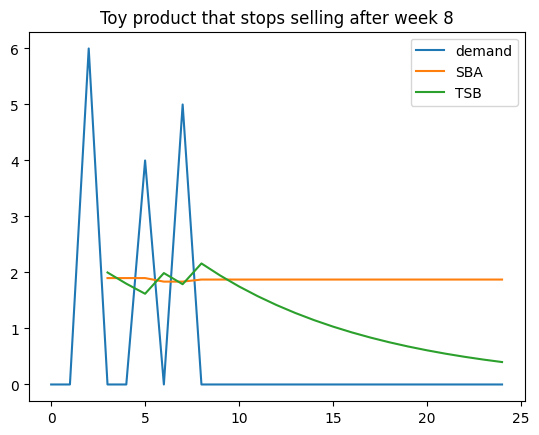

In [37]:
toy = [0, 0, 6, 0, 0, 4, 0, 5, 0, 0] + [0] * 15
f_sba, _ = sba(toy)
f_tsb, _ = tsb(toy)

ax = pd.DataFrame({"demand": toy, "SBA": f_sba, "TSB": f_tsb}).plot(
    title="Toy product that stops selling after week 8")
ax.figure.savefig(project / "images" / "toy_sba_tsb.png", dpi=150, bbox_inches="tight")

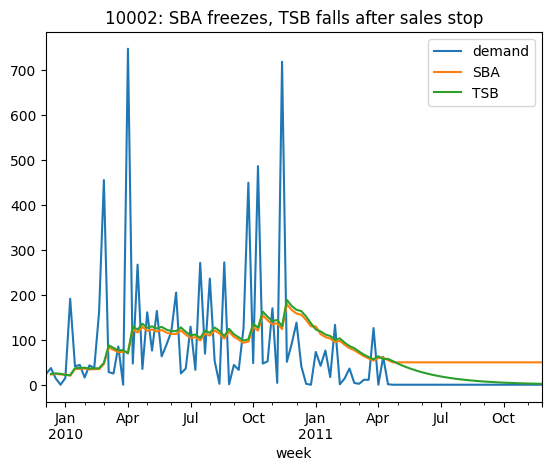

In [38]:
y = weekly[weekly["StockCode"] == "10002"].set_index("week")["qty"]
f_sba, _ = sba(y.values)
f_tsb, _ = tsb(y.values)

ax = pd.DataFrame({"demand": y, "SBA": f_sba, "TSB": f_tsb}, index=y.index).plot(
    title="10002: SBA freezes, TSB falls after sales stop")
ax.figure.savefig(project / "images" / "product_10002.png", dpi=150, bbox_inches="tight")

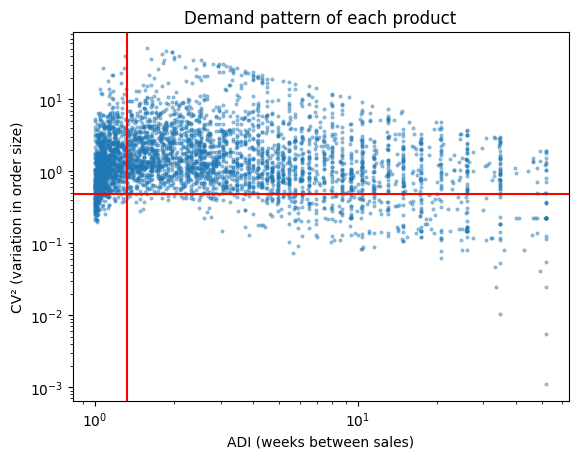

In [39]:
p = profile.dropna(subset=["adi"]).astype({"adi": float, "cv2": float})
plt.figure()
plt.scatter(p["adi"], p["cv2"], s=4, alpha=0.4)
plt.axvline(1.32, color="red"); plt.axhline(0.49, color="red")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("ADI (weeks between sales)"); plt.ylabel("CV² (variation in order size)")
plt.title("Demand pattern of each product")
plt.savefig(project / "images" / "adi_cv2.png", dpi=150, bbox_inches="tight")
plt.show()